# FTWP Chapter 1 Capstone — Payoff Explorer

## State-Dependent Option Payoffs, Expected Payoff, and Risk

### Financial Question

How do different option contracts transform the same possible future stock
values into different payoffs?

This notebook examines a call, a put, and a digital option. For each contract,
the analysis connects its financial meaning to its mathematical payoff
function, its NumPy implementation, and its state-by-state outcomes.

The analysis then uses explicitly stated probabilities to calculate and
interpret each claim's expected payoff and payoff standard deviation.

### Source and Scope

This notebook is a worked implementation and analysis of the Chapter 1
capstone in *Financial Theory with Python — Exercises*, by Yves J. Hilpisch,
The Python Quants GmbH, page 6.

The official task has four components:

1. Build a reusable function that accepts a stock payoff vector and a strike
   and returns call, put, and digital option payoffs.

2. Visualize the option payoffs as bar charts across future states.

3. Construct a table containing the expected payoff and standard deviation
   of each claim.

4. Generate random stock payoffs using a fixed seed and investigate the
   resulting option payoff shapes and convexity.

The numerical assumptions and contract conventions used in the implementation
will be stated explicitly.

### Organization

The notebook proceeds through the following sections:

1. Define the dates, future states, stock payoff vector, and strike.
2. Derive and implement the call, put, and digital payoff functions.
3. Consolidate the calculations into a reusable payoff function.
4. Visualize and interpret the state-dependent payoffs.
5. Derive expected payoff, variance, and standard deviation.
6. Conduct the reproducible random-payoff experiment.
7. Analyze payoff shape and convexity.
8. Summarize the financial conclusions and validate the implementation.

### Interpretation Boundary

The initial focus is on what each contract pays at the future date, not what
it costs today.

Expected payoff, payoff standard deviation, option price, and trading profit
will not be treated as interchangeable quantities. Each result will be
interpreted according to the financial question it actually answers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Part 1 — Dates, States, and the Financial Setup

The model has two dates:

- $t=0$: today;
- $t=1$: the future date at which the option payoff is determined.

At $t=1$, the stock can take one of two possible values:

$$
S_1
=
\begin{pmatrix}
20\\
5
\end{pmatrix}.
$$

The state ordering is

$$
(\text{Up},\text{Down}),
$$

so

$$
S_1^u=20,
\qquad
S_1^d=5.
$$

These two numbers are **not values observed at two different dates**. They are
two mutually exclusive possible stock values at the same future date.

The option strike is

$$
K=15.
$$

The strike is the contractual price against which the future stock value is
compared when determining the option payoff.

Throughout the notebook, the state ordering must remain consistent across all
payoff vectors, probability vectors, tables, and plots.

At this stage, the analysis concerns **future contractual payoffs**. It does
not yet include an option premium paid at $t=0$, so payoff should not be
interpreted as trading profit.

In [2]:
states = ["Up", "Down"]

S1 = np.array([20.0, 5.0])
K = 15.0

print("States:", states)
print("Future stock values S1:", S1)
print("Strike K:", K)
print("Shape of S1:", S1.shape)

States: ['Up', 'Down']
Future stock values S1: [20.  5.]
Strike K: 15.0
Shape of S1: (2,)


### Interpretation of the Financial Setup

The Python objects reproduce the two-state model introduced above.

The future stock payoff vector is

$$
S_1=
\begin{pmatrix}
20\\
5
\end{pmatrix},
$$

with state ordering

$$
(\text{Up},\text{Down}).
$$

Therefore,

$$
S_1^u=20,
\qquad
S_1^d=5.
$$

The array shape returned by Python is

$$
(2,),
$$

which means that `S1` is a one-dimensional NumPy array containing two
elements.

Financially, those two elements represent two mutually exclusive outcomes at
the **same future date** $t=1$.

They should not be interpreted as a time series such as

$$
20 \text{ at one date},\qquad 5 \text{ at another date}.
$$

Instead, before uncertainty is resolved, the model contains both possible
future stock values:

$$
\boxed{
S_1=
(20,5)
=
(\text{Up-state value},\text{Down-state value}).
}
$$

The strike is

$$
K=15.
$$

This number does not describe another possible stock state. It is a contractual
parameter of the option. Each option payoff will be determined by comparing
the realized stock value $S_1(\omega)$ with this strike.

The state ordering is also a computational convention that must remain
consistent throughout the notebook. If another vector later contains claim
payoffs or probabilities, its first component must correspond to the Up state
and its second component to the Down state.

This consistency is essential because NumPy operates on numerical positions.
Python does not intrinsically know that index `0` means "Up" and index `1`
means "Down"; that financial interpretation is supplied by the model.

Finally, no option price has yet been introduced.

At this stage,

$$
S_1,\quad C_1,\quad P_1,\quad D_1
$$

will represent **future payoffs** or future underlying values.

They should not yet be interpreted as

- option prices at $t=0$;
- investment returns;
- or trading profits.

A payoff describes what the contract delivers at maturity. A profit calculation
would additionally require the amount paid or received for the contract at the
initial date.

The next step is to derive the first payoff transformation: the European call
option.

## Part 2 — European Call Payoff

### Financial Meaning

A European call option gives its holder the right to buy the underlying stock
at the strike price $K$ at maturity.

At the future date $t=1$, the holder compares the realized stock value
$S_1(\omega)$ with the strike.

If

$$
S_1(\omega)>K,
$$

buying the stock for $K$ when it is worth more than $K$ creates a positive
payoff equal to

$$
S_1(\omega)-K.
$$

If

$$
S_1(\omega)\leq K,
$$

exercising would provide no positive economic benefit, so the option payoff is
zero.

Therefore, the call payoff function is

$$
\boxed{
C_1(\omega)
=
\max\left(S_1(\omega)-K,0\right).
}
$$

Equivalently, as a piecewise function,

$$
C_1(\omega)
=
\begin{cases}
S_1(\omega)-K, & S_1(\omega)>K,\\
0, & S_1(\omega)\leq K.
\end{cases}
$$

For the model

$$
S_1=(20,5),
\qquad
K=15,
$$

we first calculate the stock value relative to the strike:

$$
S_1-K
=
(20-15,\;5-15)
=
(5,-10).
$$

Now apply the call contract's zero floor.

### Up State

In the Up state,

$$
S_1^u=20>K=15,
$$

so the option is exercised and pays

$$
C_1^u
=
20-15
=
5.
$$

### Down State

In the Down state,

$$
S_1^d=5<K=15.
$$

Exercising the right to buy a stock worth $5$ for $15$ would not be rational,
so the holder does not exercise.

Therefore,

$$
C_1^d=0.
$$

The complete payoff vector is

$$
\boxed{
C_1=(5,0).
}
$$

This vector describes the option's **payoff at maturity**. It does not yet
describe the option's price at $t=0$ or the investor's profit from purchasing
the option.

In [3]:
stock_minus_strike = S1 - K
call_payoff = np.maximum(stock_minus_strike, 0.0)

print("Stock value minus strike:", stock_minus_strike)
print("Call payoff:", call_payoff)

print()
for state, stock_value, payoff in zip(states, S1, call_payoff):
    print(
        f"{state}: stock value = {stock_value:.2f}, "
        f"call payoff = {payoff:.2f}"
    )

Stock value minus strike: [  5. -10.]
Call payoff: [5. 0.]

Up: stock value = 20.00, call payoff = 5.00
Down: stock value = 5.00, call payoff = 0.00


### Derivation and Interpretation of the Call Payoff

The Python calculation returns

$$
S_1-K=(5,-10)
$$

and

$$
C_1=(5,0).
$$

This agrees with the contractual payoff rule

$$
C_1(\omega)
=
\max\left(S_1(\omega)-K,0\right).
$$

---

#### 1. Up-State Payoff

In the Up state,

$$
S_1^u=20
$$

and

$$
K=15.
$$

Therefore,

$$
S_1^u-K
=
20-15
=
5.
$$

Since this value is positive,

$$
C_1^u
=
\max(5,0)
=
5.
$$

Hence,

$$
\boxed{
C_1^u=5.
}
$$

Financially, the option gives the holder the right to buy for $15$ an asset
worth $20$ at maturity.

The resulting contractual payoff is therefore $5$.

---

#### 2. Down-State Payoff

In the Down state,

$$
S_1^d=5.
$$

Therefore,

$$
S_1^d-K
=
5-15
=
-10.
$$

A call option does not force the holder to exercise.

The holder would not choose to buy for $15$ an asset worth only $5$, so the
negative raw difference is replaced by zero:

$$
C_1^d
=
\max(-10,0)
=
0.
$$

Thus,

$$
\boxed{
C_1^d=0.
}
$$

---

#### 3. Complete State-Contingent Payoff Vector

Combining the two states gives

$$
\boxed{
C_1
=
\begin{pmatrix}
5\\
0
\end{pmatrix}.
}
$$

The first component belongs to the Up state and the second to the Down state,
consistent with the state ordering established in Part 1.

Thus,

$$
C_1
=
(C_1^u,C_1^d)
=
(5,0).
$$

---

#### 4. Why the Raw Difference and the Payoff Are Different

The intermediate vector

$$
S_1-K=(5,-10)
$$

is not itself the call payoff.

It records the stock value relative to the strike before applying the
contract's exercise rule.

The actual option payoff is

$$
\max(S_1-K,0),
$$

so negative values are replaced by zero.

Therefore,

$$
(5,-10)
\longrightarrow
(5,0).
$$

This zero floor is a fundamental feature of the call option.

---

#### 5. Python Representation

The calculation

`stock_minus_strike = S1 - K`

uses NumPy broadcasting to subtract the scalar strike from every component of
the stock payoff vector.

Then

`call_payoff = np.maximum(stock_minus_strike, 0.0)`

applies the mathematical maximum operation element by element.

Thus the Python implementation directly represents

$$
\boxed{
C_1=\max(S_1-K,0)
}
$$

state by state.

The loop used for the printed output does not perform the financial
calculation. Its purpose is only to display each state and its corresponding
stock value and claim payoff clearly.

---

#### 6. Financial Interpretation of the Payoff Shape

The call payoff is asymmetric.

If the stock finishes below or at the strike,

$$
S_1\leq K,
$$

the maturity payoff is zero.

If the stock finishes above the strike,

$$
S_1>K,
$$

the payoff increases one-for-one with the stock value:

$$
C_1=S_1-K.
$$

Therefore the payoff function has the form

$$
\boxed{
C_1(S_1)=
\begin{cases}
0, & S_1\leq K,\\
S_1-K, & S_1>K.
\end{cases}
}
$$

The strike $K$ is therefore the point at which the payoff changes from a flat
zero region to an increasing linear region.

---

#### 7. Payoff Is Not Profit

The value

$$
C_1^u=5
$$

means that the option contract pays $5$ in the Up state.

It does **not** by itself mean that the investor earns a $5$ profit.

If the option had been purchased at $t=0$ for a premium $C_0$, then a profit
calculation would also need to account for that initial cost.

This notebook has not yet introduced such a premium.

Therefore, the correct interpretation here is

$$
\boxed{
\text{call payoff}=(5,0),
}
$$

not

$$
\text{call profit}=(5,0).
$$

---

#### 8. Transition

The call benefits from sufficiently high future stock values.

The next contract has the opposite directional payoff structure: the European
put option.

## Part 3 — European Put Payoff

### Financial Meaning

A European put option gives its holder the right to sell the underlying stock
at the strike price $K$ at maturity.

The economic logic is the mirror image of the call.

If the realized stock value is below the strike,

$$
S_1(\omega)<K,
$$

the right to sell the stock for $K$ is valuable because the holder can sell at
a price above the stock's market value.

The payoff is then

$$
K-S_1(\omega).
$$

If the realized stock value is at or above the strike,

$$
S_1(\omega)\geq K,
$$

there is no benefit to exercising the right to sell for $K$, because the stock
is worth at least that much in the market.

The payoff is therefore zero.

The European put payoff function is

$$
\boxed{
P_1(\omega)
=
\max\left(K-S_1(\omega),0\right).
}
$$

Equivalently,

$$
P_1(\omega)
=
\begin{cases}
K-S_1(\omega), & S_1(\omega)<K,\\
0, & S_1(\omega)\geq K.
\end{cases}
$$

For the same stock payoff vector and strike used for the call,

$$
S_1=(20,5),
\qquad
K=15,
$$

we first calculate

$$
K-S_1
=
(15-20,\;15-5)
=
(-5,10).
$$

The put contract then applies a zero floor to this vector.

### Up State

In the Up state,

$$
S_1^u=20>K=15.
$$

Selling for $15$ an asset worth $20$ would not be advantageous, so the holder
does not exercise.

Therefore,

$$
P_1^u=0.
$$

### Down State

In the Down state,

$$
S_1^d=5<K=15.
$$

The right to sell for $15$ an asset worth only $5$ has value

$$
15-5=10.
$$

Therefore,

$$
P_1^d=10.
$$

The complete put payoff vector is

$$
\boxed{
P_1=(0,10).
}
$$

As with the call, this is a maturity payoff vector. It is not yet a time-$0$
option price or a trading-profit calculation.

In [4]:
strike_minus_stock = K - S1
put_payoff = np.maximum(strike_minus_stock, 0.0)

print("Strike minus stock value:", strike_minus_stock)
print("Put payoff:", put_payoff)

print()
for state, stock_value, payoff in zip(states, S1, put_payoff):
    print(
        f"{state}: stock value = {stock_value:.2f}, "
        f"put payoff = {payoff:.2f}"
    )

Strike minus stock value: [-5. 10.]
Put payoff: [ 0. 10.]

Up: stock value = 20.00, put payoff = 0.00
Down: stock value = 5.00, put payoff = 10.00


### Derivation and Interpretation of the Put Payoff

The Python calculation returns

$$
K-S_1=(-5,10)
$$

and

$$
P_1=(0,10).
$$

This agrees with the European put payoff rule

$$
P_1(\omega)
=
\max\left(K-S_1(\omega),0\right).
$$

---

#### 1. Up-State Payoff

In the Up state,

$$
S_1^u=20
$$

while the strike is

$$
K=15.
$$

The raw difference is

$$
K-S_1^u
=
15-20
=
-5.
$$

The put gives the holder the right to sell the stock for $15$.

If the stock is worth $20$ in the market, exercising that right would be
economically disadvantageous because the holder could sell the stock for more
in the market.

Therefore, the option is not exercised:

$$
P_1^u
=
\max(-5,0)
=
0.
$$

Hence,

$$
\boxed{
P_1^u=0.
}
$$

---

#### 2. Down-State Payoff

In the Down state,

$$
S_1^d=5.
$$

The raw difference is

$$
K-S_1^d
=
15-5
=
10.
$$

The right to sell for $15$ an asset worth only $5$ is valuable.

Therefore,

$$
P_1^d
=
\max(10,0)
=
10.
$$

Hence,

$$
\boxed{
P_1^d=10.
}
$$

---

#### 3. Complete State-Contingent Payoff Vector

Combining the two states gives

$$
\boxed{
P_1
=
\begin{pmatrix}
0\\
10
\end{pmatrix}.
}
$$

Using the established state ordering,

$$
(\text{Up},\text{Down}),
$$

the vector means

$$
P_1
=
(P_1^u,P_1^d)
=
(0,10).
$$

The first component is the payoff in the Up state and the second is the payoff
in the Down state.

---

#### 4. Why the Raw Difference Is Not the Put Payoff

The intermediate vector

$$
K-S_1=(-5,10)
$$

measures how far the strike lies above or below the stock value in each state.

It is not yet the contractual payoff.

The put holder has a **right**, not an obligation, to sell at the strike.
Therefore a negative exercise value is replaced by zero:

$$
(-5,10)
\longrightarrow
(0,10).
$$

Mathematically,

$$
P_1=\max(K-S_1,0).
$$

The zero floor is what converts the raw comparison into the actual option
payoff.

---

#### 5. Python Representation

The calculation

`strike_minus_stock = K - S1`

subtracts each future stock value from the scalar strike.

Because `S1` is a NumPy array,

$$
K-S_1
=
(15-20,\;15-5)
=
(-5,10)
$$

is calculated element by element.

Then

`put_payoff = np.maximum(strike_minus_stock, 0.0)`

implements the zero floor componentwise:

$$
\max(-5,0)=0,
$$

$$
\max(10,0)=10.
$$

Thus, the Python expression is a direct numerical representation of

$$
\boxed{
P_1=\max(K-S_1,0).
}
$$

As in the call section, the loop used afterward only formats the state-by-state
output for readability. It does not determine the payoff itself.

---

#### 6. Payoff Shape

The put payoff moves in the opposite direction from the call payoff.

If

$$
S_1<K,
$$

the put payoff is

$$
P_1=K-S_1.
$$

As the stock value falls further below the strike, the payoff increases.

If

$$
S_1\geq K,
$$

the put payoff is zero.

Therefore,

$$
\boxed{
P_1(S_1)
=
\begin{cases}
K-S_1, & S_1<K,\\
0, & S_1\geq K.
\end{cases}
}
$$

The put therefore has a decreasing linear payoff region below the strike and a
flat zero-payoff region at and above the strike.

---

#### 7. Call and Put Comparison

For the same stock states and the same strike,

$$
S_1=(20,5),
\qquad
K=15,
$$

the call payoff is

$$
C_1=(5,0),
$$

while the put payoff is

$$
P_1=(0,10).
$$

This illustrates their opposite directional exposure:

- the call benefits from sufficiently high stock values;
- the put benefits from sufficiently low stock values.

Neither contract produces a negative payoff to its holder at maturity because
exercise is optional.

---

#### 8. Payoff Is Still Not Profit

The Down-state value

$$
P_1^d=10
$$

means that the put contract pays $10 in that state.

It does not mean that purchasing the put generated a $10 profit.

A profit calculation would also require the option premium paid at $t=0$ and,
depending on the accounting convention, potentially the time value of that
initial cash flow.

No option premium has been introduced in this notebook.

Therefore,

$$
\boxed{
\text{put payoff}=(0,10)
}
$$

is the appropriate interpretation at this stage.

---

#### 9. Transition

The call and put payoffs vary with the magnitude of the stock's movement beyond
the strike.

The next contract is structurally different.

A digital option does not pay more simply because the stock moves farther past
the strike. Instead, it pays a fixed amount when a specified condition is met.

This introduces a different type of state-dependent payoff transformation.

## Part 4 — Digital Option Payoff

### Financial Meaning

A digital option has a different payoff structure from the call and put.

For this notebook, I use a one-unit **cash-or-nothing digital call**.

The contract pays a fixed amount of one unit if the stock finishes strictly
above the strike and zero otherwise.

The payoff rule is

$$
\boxed{
D_1(\omega)
=
\begin{cases}
1, & S_1(\omega)>K,\\
0, & S_1(\omega)\leq K.
\end{cases}
}
$$

This strict-inequality convention is an explicit modeling choice for this
implementation.

Therefore, if

$$
S_1=K,
$$

the digital payoff is zero.

Unlike an ordinary call, the digital payoff does not continue increasing as
the stock moves farther above the strike.

Once the condition

$$
S_1>K
$$

is satisfied, the payoff is simply one unit.

For

$$
S_1=(20,5),
\qquad
K=15,
$$

the two states are evaluated as follows.

### Up State

In the Up state,

$$
S_1^u=20>15.
$$

The payoff condition is satisfied, so

$$
D_1^u=1.
$$

### Down State

In the Down state,

$$
S_1^d=5<15.
$$

The payoff condition is not satisfied, so

$$
D_1^d=0.
$$

Therefore, the complete digital payoff vector is

$$
\boxed{
D_1=(1,0).
}
$$

This is a fixed state-contingent maturity payoff. It is not an option price,
probability, return, or trading profit.

In [5]:
digital_condition = S1 > K
digital_payoff = digital_condition.astype(float)

print("Condition S1 > K:", digital_condition)
print("Digital payoff:", digital_payoff)

print()
for state, stock_value, condition, payoff in zip(
    states, S1, digital_condition, digital_payoff
):
    print(
        f"{state}: stock value = {stock_value:.2f}, "
        f"S1 > K = {condition}, "
        f"digital payoff = {payoff:.2f}"
    )

Condition S1 > K: [ True False]
Digital payoff: [1. 0.]

Up: stock value = 20.00, S1 > K = True, digital payoff = 1.00
Down: stock value = 5.00, S1 > K = False, digital payoff = 0.00


### Derivation and Interpretation of the Digital Payoff

The Python calculation first evaluates the condition

$$
S_1>K.
$$

For

$$
S_1=(20,5),
\qquad
K=15,
$$

this gives

$$
(20>15,\;5>15)
=
(\mathrm{True},\mathrm{False}).
$$

Python therefore returns the Boolean array

$$
(\mathrm{True},\mathrm{False}).
$$

The second step converts these logical values into numerical cash payoffs:

$$
\mathrm{True}\longrightarrow1,
\qquad
\mathrm{False}\longrightarrow0.
$$

Hence,

$$
\boxed{
D_1=(1,0).
}
$$

---

#### 1. Up-State Payoff

In the Up state,

$$
S_1^u=20.
$$

Because

$$
20>15,
$$

the digital condition is satisfied.

Therefore,

$$
D_1^u=1.
$$

Hence,

$$
\boxed{
D_1^u=1.
}
$$

The size of the stock's excess above the strike does not matter once the
condition is satisfied.

For example, under this contract specification, a maturity stock value of $16,
$20, or $100 would all produce the same digital payoff:

$$
D_1=1.
$$

---

#### 2. Down-State Payoff

In the Down state,

$$
S_1^d=5.
$$

Because

$$
5>15
$$

is false, the contract does not pay.

Therefore,

$$
D_1^d=0.
$$

Hence,

$$
\boxed{
D_1^d=0.
}
$$

---

#### 3. Complete State-Contingent Payoff Vector

Combining the two states gives

$$
\boxed{
D_1
=
\begin{pmatrix}
1\\
0
\end{pmatrix}.
}
$$

Using the established ordering

$$
(\text{Up},\text{Down}),
$$

this means

$$
D_1=(D_1^u,D_1^d)=(1,0).
$$

---

#### 4. The Payoff-at-Strike Convention

The implementation uses the strict condition

$$
S_1>K.
$$

Therefore, if the stock finishes exactly at the strike,

$$
S_1=K,
$$

the logical condition is false and the payoff is

$$
D_1=0.
$$

Thus, the payoff function used in this notebook is

$$
\boxed{
D_1(S_1)
=
\begin{cases}
0, & S_1\leq K,\\
1, & S_1>K.
\end{cases}
}
$$

This convention is stated explicitly because a digital contract must specify
what happens at the threshold.

---

#### 5. Python Representation

The expression

`digital_condition = S1 > K`

does not initially produce numerical option payoffs.

It produces Boolean values:

$$
\mathrm{True}
\quad\text{or}\quad
\mathrm{False}.
$$

The expression

`digital_condition.astype(float)`

then converts

$$
\mathrm{True}\rightarrow1.0
$$

and

$$
\mathrm{False}\rightarrow0.0.
$$

Therefore,

`digital_payoff = digital_condition.astype(float)`

is the numerical implementation of the cash-or-nothing payoff rule.

The loop following the calculation serves only to display the state-by-state
logic clearly. It does not determine the payoff.

---

#### 6. How the Digital Differs From the Call

The call and digital options both become active when the stock is sufficiently
high, but their payoff structures are fundamentally different.

For the call,

$$
C_1(S_1)
=
\max(S_1-K,0).
$$

Once

$$
S_1>K,
$$

the call payoff continues to increase as the stock rises.

By contrast, the digital payoff is

$$
D_1(S_1)
=
\begin{cases}
0, & S_1\leq K,\\
1, & S_1>K.
\end{cases}
$$

Once the threshold is crossed, the payment remains fixed at one unit.

Therefore,

$$
\boxed{
\text{call payoff depends on how far }S_1\text{ exceeds }K,
}
$$

whereas

$$
\boxed{
\text{digital payoff depends only on whether }S_1>K.
}
$$

---

#### 7. Comparing All Three Contracts

For the same stock payoff vector

$$
S_1=(20,5)
$$

and strike

$$
K=15,
$$

the three contracts produce

$$
\boxed{
C_1=(5,0)
}
$$

for the call,

$$
\boxed{
P_1=(0,10)
}
$$

for the put, and

$$
\boxed{
D_1=(1,0)
}
$$

for the digital.

These payoff vectors summarize three different transformations of the same
underlying stock uncertainty:

- the **call** rewards sufficiently high stock values and increases with the
  amount above the strike;
- the **put** rewards sufficiently low stock values and increases as the stock
  falls farther below the strike;
- the **digital** pays a fixed amount once a threshold condition is satisfied.

The three claims therefore respond differently to the same underlying future
state.

---

#### 8. Payoff Shape

The digital payoff has a threshold or step structure.

Below and at the strike,

$$
D_1=0.
$$

Immediately above the strike,

$$
D_1=1.
$$

Unlike the call and put, there is no linear payoff region after the threshold.
The payoff jumps from zero to one and then remains constant.

This difference in payoff geometry will become important later when the
contracts are compared across a larger set of randomly generated stock values.

---

#### 9. Payoff Is Not Probability or Price

The value

$$
D_1^u=1
$$

is a contractual cash payoff.

It does not mean that the Up state has probability one, nor does it mean that
the digital option is worth one unit at $t=0$.

At this stage,

$$
D_1=(1,0)
$$

describes only the contract's state-dependent maturity payoff.

Pricing the contract would require additional financial structure that is not
part of this section.

---

#### 10. Transition

The call, put, and digital payoffs have now been derived separately and
verified numerically.

The next step is to consolidate these three contract rules into a single
reusable function.

This turns the individual calculations into a small payoff engine that can be
applied consistently to both the original two-state example and the later
random-payoff experiment.

## Part 5 — Building a Reusable Payoff Function

The call, put, and digital payoffs have now been derived and verified
individually.

Rather than repeat the same three formulas every time the stock payoff vector
or strike changes, the next step is to package the contract definitions into a
single reusable function.

The function will take two inputs:

$$
S_1
$$

the vector of possible stock values at maturity, and

$$
K
$$

the option strike.

It will return three payoff vectors:

$$
C_1=\max(S_1-K,0),
$$

$$
P_1=\max(K-S_1,0),
$$

and, using the convention adopted in this notebook,

$$
D_1=
\mathbf{1}_{\{S_1>K\}}.
$$

Here,

$$
\mathbf{1}_{\{S_1>K\}}
$$

is an indicator function: it equals one when the condition $S_1>K$ is true
and zero otherwise.

The objective is therefore to create the mapping

$$
\boxed{
(S_1,K)
\longmapsto
(C_1,P_1,D_1).
}
$$

This is useful for two reasons.

First, the financial definitions are stored in one place, reducing the risk of
using inconsistent formulas in later sections.

Second, the same function can be applied to a larger collection of stock
payoffs in the random-state experiment without changing the contract logic.

After defining the function, I verify that it reproduces the payoff vectors
already derived by hand for the original two-state example.

In [6]:
def option_payoffs(stock_payoffs, strike):
    """
    Return European call, put, and one-unit digital-call payoffs.

    Parameters
    ----------
    stock_payoffs : np.ndarray
        Possible stock values at maturity.
    strike : float
        Option strike price.

    Returns
    -------
    call : np.ndarray
        max(stock_payoffs - strike, 0)
    put : np.ndarray
        max(strike - stock_payoffs, 0)
    digital : np.ndarray
        1 when stock_payoffs > strike, otherwise 0
    """
    call = np.maximum(stock_payoffs - strike, 0.0)
    put = np.maximum(strike - stock_payoffs, 0.0)
    digital = (stock_payoffs > strike).astype(float)

    return call, put, digital


call_from_function, put_from_function, digital_from_function = option_payoffs(
    S1, K
)

print("Call from function:", call_from_function)
print("Put from function:", put_from_function)
print("Digital from function:", digital_from_function)

print()
print(
    "Call matches earlier calculation:",
    np.allclose(call_from_function, call_payoff)
)
print(
    "Put matches earlier calculation:",
    np.allclose(put_from_function, put_payoff)
)
print(
    "Digital matches earlier calculation:",
    np.allclose(digital_from_function, digital_payoff)
)

Call from function: [5. 0.]
Put from function: [ 0. 10.]
Digital from function: [1. 0.]

Call matches earlier calculation: True
Put matches earlier calculation: True
Digital matches earlier calculation: True


### Derivation and Interpretation of the Reusable Payoff Function

The reusable function returns

$$
C_1=(5,0),
$$

$$
P_1=(0,10),
$$

and

$$
D_1=(1,0).
$$

These are exactly the payoff vectors derived independently in Parts 2–4.

The three verification checks also return `True`, confirming that the function
reproduces the previously established calculations.

---

#### 1. Function Inputs

The function is defined as

`option_payoffs(stock_payoffs, strike)`.

It accepts two inputs.

The first input,

`stock_payoffs`,

represents the vector of possible stock values at maturity.

Mathematically,

$$
\text{stock\_payoffs}
\equiv
S_1.
$$

For the current example,

$$
S_1=(20,5).
$$

The second input,

`strike`,

represents the option strike price.

Mathematically,

$$
\text{strike}
\equiv
K.
$$

For the current example,

$$
K=15.
$$

The function therefore receives the financial objects

$$
(S_1,K)
$$

and transforms them into three contingent-claim payoff vectors.

---

#### 2. Local Call Payoff Calculation

Inside the function,

`call = np.maximum(stock_payoffs - strike, 0.0)`

implements

$$
C_1=\max(S_1-K,0).
$$

For the current inputs,

$$
S_1-K=(5,-10),
$$

so

$$
C_1=(5,0).
$$

The name `call` is local to the function. It temporarily stores the call payoff
while the function is executing.

---

#### 3. Local Put Payoff Calculation

The line

`put = np.maximum(strike - stock_payoffs, 0.0)`

implements

$$
P_1=\max(K-S_1,0).
$$

For the current inputs,

$$
K-S_1=(-5,10),
$$

so

$$
P_1=(0,10).
$$

Again, `put` is a local variable containing the calculated payoff vector.

---

#### 4. Local Digital Payoff Calculation

The line

`digital = (stock_payoffs > strike).astype(float)`

implements the digital-call convention

$$
D_1=
\mathbf{1}_{\{S_1>K\}}.
$$

For the current stock values,

$$
(20>15,\;5>15)
=
(\mathrm{True},\mathrm{False}),
$$

which is converted to

$$
D_1=(1,0).
$$

Thus, all three contract definitions are encoded inside the same function.

---

#### 5. The Meaning of `return`

The final line of the function is

`return call, put, digital`.

This sends the three calculated payoff arrays back to the code that called the
function.

Conceptually, the function performs the mapping

$$
\boxed{
(S_1,K)
\longmapsto
(C_1,P_1,D_1).
}
$$

The three returned objects preserve the order

$$
(\text{call},\text{put},\text{digital}).
$$

That order matters when the results are assigned to names outside the function.

---

#### 6. Ordered Unpacking of the Returned Values

The function is called with

`option_payoffs(S1, K)`.

Its three returned arrays are assigned using

`call_from_function, put_from_function, digital_from_function = ...`

This is ordered unpacking.

The first returned value is assigned to

`call_from_function`,

the second to

`put_from_function`,

and the third to

`digital_from_function`.

Therefore,

$$
\begin{aligned}
\text{call\_from\_function} &= C_1,\\
\text{put\_from\_function} &= P_1,\\
\text{digital\_from\_function} &= D_1.
\end{aligned}
$$

The variable names outside the function do not need to match the local names
inside it, but the return order must remain consistent.

---

#### 7. Why the Verification Checks Matter

The notebook does not accept the reusable function merely because its output
looks reasonable.

Each result is compared with a payoff vector that was already derived and
computed independently.

For example,

`np.allclose(call_from_function, call_payoff)`

asks whether the call payoff returned by the function is numerically equal to
the earlier call calculation.

The same check is performed for the put and digital payoffs.

The output

`True`

for all three cases establishes

$$
\boxed{
C_1^{\mathrm{function}}
=
C_1^{\mathrm{earlier}},
}
$$

$$
\boxed{
P_1^{\mathrm{function}}
=
P_1^{\mathrm{earlier}},
}
$$

and

$$
\boxed{
D_1^{\mathrm{function}}
=
D_1^{\mathrm{earlier}}.
}
$$

This gives the implementation a simple internal consistency check.

---

#### 8. Why a Reusable Function Improves the Analysis

Without a reusable function, every new stock-payoff experiment would require
rewriting the three option formulas separately.

That creates unnecessary repetition and increases the chance of introducing
inconsistent logic.

By defining the contract rules once, the notebook can now change

$$
S_1
$$

or

$$
K
$$

while preserving the same payoff definitions.

This becomes particularly important in the later random-payoff experiment,
where the same contracts will be evaluated across many stock outcomes.

The function therefore separates two ideas:

$$
\boxed{
\text{contract definition}
}
$$

from

$$
\boxed{
\text{particular numerical experiment}.
}
$$

That separation is useful both financially and computationally.

---

#### 9. Scope of the Function

The function is intentionally simple.

It assumes that `stock_payoffs` is a NumPy-compatible collection of maturity
stock values and that `strike` is a numerical strike value.

The official capstone requires a reusable payoff function, but does not require
a full input-validation framework.

For this portfolio artifact, the emphasis is therefore on transparent financial
logic, correct vectorized implementation, and reproducible analysis rather than
building a general-purpose options software library.

---

#### 10. Transition

The notebook now has a verified payoff engine that can generate all three
claims consistently.

The next step is to visualize the payoff vectors across states.

This changes the question from

$$
\text{What numbers does each contract return?}
$$

to

$$
\text{How do the contracts distribute payoff across future states?}
$$

The visualization will make the different payoff structures easier to compare
before expectations and risk measures are introduced.

## Part 6 — Visualizing Payoffs Across States

The payoff vectors derived above are

$$
C_1=(5,0),
$$

$$
P_1=(0,10),
$$

and

$$
D_1=(1,0).
$$

A table is useful for exact numerical comparison, while a bar chart makes the
state dependence of each contract visually immediate.

The visualization below therefore serves two purposes:

1. compare the three contracts within each future state;
2. show how different payoff rules transform the same underlying stock
   uncertainty.

The chart uses the established state ordering

$$
(\text{Up},\text{Down}).
$$

The bar heights represent **maturity payoffs**.

They do not represent

- probabilities;
- option prices at $t=0$;
- expected returns;
- or trading profits.

Because the digital contract pays only one unit when triggered, its bar is
naturally smaller than the call and put bars in this numerical example. That
difference reflects the contract specification, not a lower probability of the
corresponding state.

State-dependent payoff table:


,Stock value,Call payoff,Put payoff,Digital payoff
Up,20.0,5.0,0.0,1.0
Down,5.0,0.0,10.0,0.0


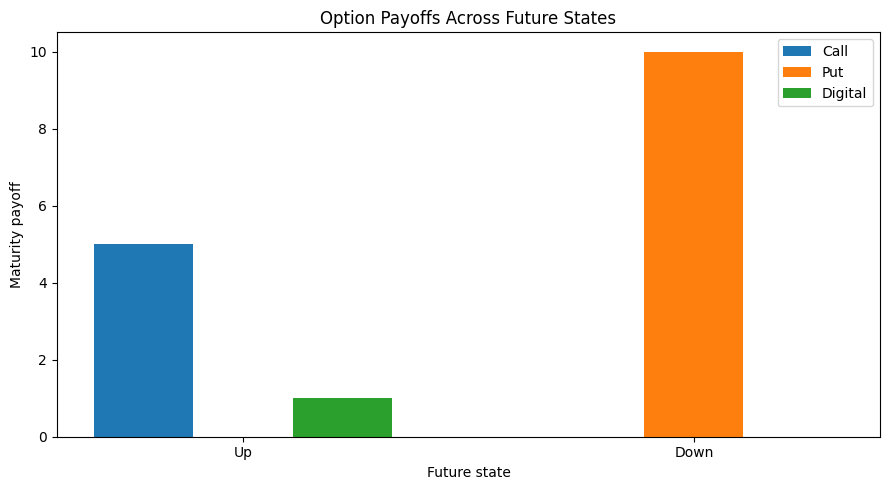

In [7]:
payoff_table = pd.DataFrame(
    {
        "Stock value": S1,
        "Call payoff": call_from_function,
        "Put payoff": put_from_function,
        "Digital payoff": digital_from_function,
    },
    index=states,
)

print("State-dependent payoff table:")
display(payoff_table)

x = np.arange(len(states))
width = 0.22

plt.figure(figsize=(9, 5))

plt.bar(
    x - width,
    call_from_function,
    width,
    label="Call",
)

plt.bar(
    x,
    put_from_function,
    width,
    label="Put",
)

plt.bar(
    x + width,
    digital_from_function,
    width,
    label="Digital",
)

plt.xticks(x, states)
plt.xlabel("Future state")
plt.ylabel("Maturity payoff")
plt.title("Option Payoffs Across Future States")
plt.legend()

plt.tight_layout()
plt.show()

### Interpretation of the Payoff Visualization

The table and grouped bar chart summarize how the same two future stock states
generate different maturity cash flows under the three option contracts.

For the stock payoff vector

$$
S_1=(20,5)
$$

and strike

$$
K=15,
$$

the resulting claim payoffs are

$$
C_1=(5,0),
$$

$$
P_1=(0,10),
$$

and

$$
D_1=(1,0).
$$

The state-by-state comparison is therefore

| State | Stock value | Call payoff | Put payoff | Digital payoff |
|---|---:|---:|---:|---:|
| Up | $20$ | $5$ | $0$ | $1$ |
| Down | $5$ | $0$ | $10$ | $0$ |

---

#### 1. Up State

In the Up state,

$$
S_1^u=20>K.
$$

The call is in the money and pays

$$
20-15=5.
$$

The put is out of the money and pays

$$
0.
$$

The digital condition

$$
S_1^u>K
$$

is satisfied, so the digital pays its fixed amount of

$$
1.
$$

Hence the Up-state payoff vector across the three contracts is

$$
\boxed{
(C_1^u,P_1^u,D_1^u)=(5,0,1).
}
$$

---

#### 2. Down State

In the Down state,

$$
S_1^d=5<K.
$$

The call is out of the money and pays

$$
0.
$$

The put is in the money and pays

$$
15-5=10.
$$

The digital condition

$$
S_1^d>K
$$

is false, so the digital pays

$$
0.
$$

Hence the Down-state payoff vector across the three contracts is

$$
\boxed{
(C_1^d,P_1^d,D_1^d)=(0,10,0).
}
$$

---

#### 3. What the Chart Makes Visible

The chart shows that each contract transforms the same underlying uncertainty
in a different way.

The **call** concentrates payoff in the high-stock state:

$$
C_1=(5,0).
$$

The **put** concentrates payoff in the low-stock state:

$$
P_1=(0,10).
$$

The **digital call** also pays in the high-stock state, but its payoff is fixed
once the threshold is crossed:

$$
D_1=(1,0).
$$

Thus the call and digital respond to the same directional event in this
two-state example, but they do not have the same payoff sensitivity.

---

#### 4. Magnitude Versus Trigger

The call payoff depends on the magnitude by which the stock exceeds the strike:

$$
C_1=S_1-K
\qquad
\text{when }S_1>K.
$$

The digital payoff depends only on whether the threshold condition is true:

$$
D_1=1
\qquad
\text{when }S_1>K.
$$

Therefore, if the stock finished even farther above the strike, the call payoff
would increase while the one-unit digital payoff would remain fixed at one.

This distinction is not obvious from the condition

$$
S_1>K
$$

alone; it becomes clear when the payoff functions are compared directly.

---

#### 5. Why the Digital Bar Is Smaller

The digital bar is numerically smaller than the Up-state call bar because this
notebook defines the digital contract to pay exactly one unit when triggered.

Thus,

$$
D_1^u=1
$$

while

$$
C_1^u=5.
$$

The smaller bar does **not** imply

- that the Up state is less probable;
- that the digital contract is necessarily less risky;
- or that its time-$0$ price must be lower by the same proportion.

The chart displays contractual maturity cash flows only.

---

#### 6. State Dependence and Contingent Claims

Each option is a contingent claim because its payoff depends on which future
state occurs.

The stock itself has payoff vector

$$
S_1=(20,5),
$$

while the option contracts transform those underlying outcomes into new payoff
vectors:

$$
S_1
\longrightarrow
C_1,
$$

$$
S_1
\longrightarrow
P_1,
$$

and

$$
S_1
\longrightarrow
D_1.
$$

The option therefore does not create a new future state.

Instead, it specifies a different cash flow for each existing state of the
underlying model.

---

#### 7. What the Visualization Does Not Yet Tell Us

The chart answers the question

$$
\text{What does each contract pay in each state?}
$$

It does not yet answer

$$
\text{What is the average payoff before the state is known?}
$$

or

$$
\text{How dispersed are the possible payoffs around that average?}
$$

To answer those questions, the model must introduce probabilities for the
future states.

Once a probability vector is specified, the next section will calculate

$$
E[X]
$$

for expected payoff and

$$
\sigma_X
$$

for payoff standard deviation.

These quantities will summarize the center and dispersion of each claim's
state-dependent payoff distribution.

## Part 7 — Expected Payoff and Payoff Risk

The previous sections describe what each option pays **after a particular state
is realized**.

Before the future state is known, a different question arises:

> Given probabilities for the possible states, what is the average payoff we
> expect from each claim, and how dispersed are its possible payoffs around
> that average?

To answer this question, the model now introduces a probability vector.

### Probability Assumption

The Chapter 1 capstone requires expected payoff and standard deviation but does
not prescribe a probability distribution over the states.

For this numerical experiment, I assume that the Up and Down states are equally
likely:

$$
P=
\begin{pmatrix}
0.5\\
0.5
\end{pmatrix}.
$$

Thus,

$$
P(\text{Up})=0.5,
\qquad
P(\text{Down})=0.5,
$$

and

$$
0.5+0.5=1.
$$

This is an explicit modeling assumption used to summarize the payoff
distributions. It is not inferred from the option payoffs themselves.

---

### 1. Expected Payoff

For a contingent claim

$$
X=
\begin{pmatrix}
X^u\\
X^d
\end{pmatrix},
$$

the expected payoff under probability vector $P$ is

$$
E_P[X]
=
p_uX^u+p_dX^d.
$$

In vector notation,

$$
\boxed{
E_P[X]=P^\top X.
}
$$

With equal probabilities,

$$
E_P[X]
=
0.5X^u+0.5X^d.
$$

The expected payoff is therefore a probability-weighted average of the
possible maturity cash flows.

It is not a third state and it need not equal any payoff that is actually
realized.

---

### 2. Call Expected Payoff

The call payoff is

$$
C_1=(5,0).
$$

Therefore,

$$
E_P[C_1]
=
0.5(5)+0.5(0)
=
2.5.
$$

Hence,

$$
\boxed{
E_P[C_1]=2.5.
}
$$

The call pays either $5$ or $0$ in this model, but its ex-ante expected payoff
under the assumed probabilities is $2.5$.

---

### 3. Put Expected Payoff

The put payoff is

$$
P_1=(0,10).
$$

Therefore,

$$
E_P[P_1]
=
0.5(0)+0.5(10)
=
5.
$$

Hence,

$$
\boxed{
E_P[P_1]=5.
}
$$

---

### 4. Digital Expected Payoff

The digital payoff is

$$
D_1=(1,0).
$$

Therefore,

$$
E_P[D_1]
=
0.5(1)+0.5(0)
=
0.5.
$$

Hence,

$$
\boxed{
E_P[D_1]=0.5.
}
$$

For this one-unit digital contract, the expected payoff equals $0.5$ because
the contract pays one unit in exactly one of two equally likely states.

This numerical equality should not be confused with an option price.

---

### 5. Variance of a Payoff

Expected payoff describes the center of the payoff distribution.

To measure dispersion around that center, define the payoff variance as

$$
\operatorname{Var}_P(X)
=
E_P\left[
\left(
X-E_P[X]
\right)^2
\right].
$$

For the two-state model,

$$
\boxed{
\operatorname{Var}_P(X)
=
p_u(X^u-E_P[X])^2
+
p_d(X^d-E_P[X])^2.
}
$$

The deviations are squared for two reasons:

1. positive and negative deviations should not cancel;
2. larger deviations receive greater weight.

Variance is measured in squared payoff units, so its square root is often more
directly interpretable.

---

### 6. Standard Deviation

The payoff standard deviation is

$$
\boxed{
\sigma_X
=
\sqrt{
\operatorname{Var}_P(X)
}.
}
$$

Standard deviation is expressed in the same units as the payoff itself.

In this notebook it measures how dispersed the claim's possible maturity
payoffs are around its expected payoff under the assumed probability
distribution.

---

### 7. Call Variance and Standard Deviation

For the call,

$$
C_1=(5,0)
$$

with

$$
E_P[C_1]=2.5.
$$

The deviations from the expected payoff are

$$
5-2.5=2.5
$$

and

$$
0-2.5=-2.5.
$$

Therefore,

$$
\operatorname{Var}_P(C_1)
=
0.5(2.5)^2
+
0.5(-2.5)^2.
$$

Hence,

$$
\operatorname{Var}_P(C_1)
=
6.25,
$$

and

$$
\boxed{
\sigma_C
=
\sqrt{6.25}
=
2.5.
}
$$

---

### 8. Put Variance and Standard Deviation

For the put,

$$
P_1=(0,10)
$$

with

$$
E_P[P_1]=5.
$$

The deviations are

$$
0-5=-5
$$

and

$$
10-5=5.
$$

Therefore,

$$
\operatorname{Var}_P(P_1)
=
0.5(-5)^2
+
0.5(5)^2
=
25.
$$

Thus,

$$
\boxed{
\sigma_P=5.
}
$$

---

### 9. Digital Variance and Standard Deviation

For the digital,

$$
D_1=(1,0)
$$

with

$$
E_P[D_1]=0.5.
$$

The deviations are

$$
1-0.5=0.5
$$

and

$$
0-0.5=-0.5.
$$

Therefore,

$$
\operatorname{Var}_P(D_1)
=
0.5(0.5)^2
+
0.5(-0.5)^2
=
0.25.
$$

Thus,

$$
\boxed{
\sigma_D=0.5.
}
$$

---

### 10. Expected Results Before Python

The hand calculations imply the following table:

| Claim | Expected payoff | Variance | Standard deviation |
|---|---:|---:|---:|
| Call | $2.5$ | $6.25$ | $2.5$ |
| Put | $5.0$ | $25.0$ | $5.0$ |
| Digital | $0.5$ | $0.25$ | $0.5$ |

The next code cell implements these definitions and verifies that the numerical
results reproduce the hand calculations.

In [8]:
P = np.array([0.5, 0.5])

print("State probabilities:", P)
print("Probability sum:", P.sum())


def payoff_moments(payoff, probabilities):
    """Return expected payoff, variance, and standard deviation."""
    expected_payoff = np.dot(probabilities, payoff)
    variance = np.dot(
        probabilities,
        (payoff - expected_payoff) ** 2,
    )
    standard_deviation = np.sqrt(variance)

    return expected_payoff, variance, standard_deviation


claim_payoffs = {
    "Call": call_from_function,
    "Put": put_from_function,
    "Digital": digital_from_function,
}

statistics_rows = []

for claim_name, payoff in claim_payoffs.items():
    expected_payoff, variance, standard_deviation = payoff_moments(
        payoff, P
    )

    statistics_rows.append(
        {
            "Claim": claim_name,
            "Expected Payoff": expected_payoff,
            "Variance": variance,
            "Standard Deviation": standard_deviation,
        }
    )

statistics_table = pd.DataFrame(statistics_rows).set_index("Claim")

print()
print("Payoff statistics:")
display(statistics_table)

State probabilities: [0.5 0.5]
Probability sum: 1.0

Payoff statistics:


,Expected Payoff,Variance,Standard Deviation
Claim,,,
Call,2.5,6.25,2.5
Put,5.0,25.00,5.0
Digital,0.5,0.25,0.5


### Interpretation of Expected Payoff and Payoff Risk

The Python results reproduce the hand calculations exactly.

The assumed state-probability vector is

$$
P=(0.5,0.5),
$$

and Python confirms

$$
\sum_{\omega}P(\omega)=1.
$$

Under this probability model, the payoff statistics are:

| Claim | Expected payoff | Variance | Standard deviation |
|---|---:|---:|---:|
| Call | $2.5$ | $6.25$ | $2.5$ |
| Put | $5.0$ | $25.0$ | $5.0$ |
| Digital | $0.5$ | $0.25$ | $0.5$ |

---

#### 1. Call Payoff Distribution

The call payoff is

$$
C_1=(5,0).
$$

Each state has probability $0.5$, so

$$
E_P[C_1]
=
0.5(5)+0.5(0)
=
2.5.
$$

The standard deviation is

$$
\sigma_C=2.5.
$$

Thus the call's possible maturity payoffs lie symmetrically around its expected
payoff:

$$
5-2.5=2.5,
$$

and

$$
0-2.5=-2.5.
$$

The call therefore has expected payoff

$$
\boxed{E_P[C_1]=2.5}
$$

and payoff standard deviation

$$
\boxed{\sigma_C=2.5}.
$$

---

#### 2. Put Payoff Distribution

The put payoff is

$$
P_1=(0,10).
$$

Its expected payoff is

$$
E_P[P_1]
=
0.5(0)+0.5(10)
=
5.
$$

Its standard deviation is

$$
\sigma_P=5.
$$

The two possible payoffs differ from the mean by

$$
-5
$$

and

$$
+5.
$$

Therefore,

$$
\boxed{E_P[P_1]=5}
$$

and

$$
\boxed{\sigma_P=5}.
$$

---

#### 3. Digital Payoff Distribution

The digital payoff is

$$
D_1=(1,0).
$$

Its expected payoff is

$$
E_P[D_1]
=
0.5(1)+0.5(0)
=
0.5.
$$

Its standard deviation is

$$
\sigma_D=0.5.
$$

Therefore,

$$
\boxed{E_P[D_1]=0.5}
$$

and

$$
\boxed{\sigma_D=0.5}.
$$

Because this particular digital contract pays exactly one unit when the event

$$
S_1>K
$$

occurs and zero otherwise, its expected payoff has a special interpretation:

$$
E_P[D_1]
=
1\cdot P(S_1>K)
+
0\cdot P(S_1\leq K).
$$

Hence,

$$
\boxed{
E_P[D_1]=P(S_1>K)=0.5
}
$$

for this one-unit digital payoff.

This equality holds because the payoff itself is an indicator variable. It
does not mean that an arbitrary option's expected payoff can be interpreted as
a probability.

---

#### 4. Expected Payoff Is Not a Future State

The expected payoff is an ex-ante probability-weighted average.

For example,

$$
E_P[C_1]=2.5,
$$

but the call never actually pays $2.5$ in this two-state model.

Its only possible realized payoffs are

$$
5
$$

and

$$
0.
$$

Thus,

$$
\boxed{
\text{expected payoff}
\neq
\text{an additional possible state payoff}.
}
$$

Expectation summarizes the distribution before uncertainty is resolved.

---

#### 5. Standard Deviation as Payoff Dispersion

The standard deviation measures how far the possible payoffs tend to lie from
their expected payoff.

For the three contracts,

$$
\sigma_C=2.5,
$$

$$
\sigma_P=5,
$$

and

$$
\sigma_D=0.5.
$$

Within this specific numerical experiment, the put has the largest absolute
payoff dispersion.

However, this does **not** establish that the put is universally the "riskiest"
of the three contracts.

The contracts have different payoff scales:

- the put can pay $10$ in this example;
- the call can pay $5$;
- the digital is deliberately defined to pay only one unit.

Multiplying any contract payoff by a constant would multiply its standard
deviation by the same constant.

Therefore, raw standard deviations should be interpreted in the context of the
contract's payoff scale and specification.

The correct statement here is

$$
\boxed{
\text{the put has the greatest payoff dispersion in this particular model and
contract scaling.}
}
$$

---

#### 6. Expected Payoff Is Not Option Price

The values

$$
2.5,\qquad5,\qquad0.5
$$

are expectations calculated under the explicitly assumed probability vector

$$
P=(0.5,0.5).
$$

They are not automatically arbitrage-free option prices at $t=0$.

Pricing a contingent claim requires additional financial structure, such as
replication, state prices, or a suitable martingale measure.

Those pricing ideas belong to later parts of the financial-theory sequence.

Therefore,

$$
\boxed{
E_P[X]
\text{ is a statistical summary of future payoff, not automatically }X_0.
}
$$

This distinction between physical payoff expectations and financial prices is
important throughout quantitative finance.

---

#### 7. What the Python Function Represents

The helper function

`payoff_moments(payoff, probabilities)`

implements three mathematical operations in sequence.

First,

`np.dot(probabilities, payoff)`

computes

$$
E_P[X].
$$

Second,

`np.dot(probabilities, (payoff - expected_payoff) ** 2)`

computes

$$
\operatorname{Var}_P(X).
$$

Third,

`np.sqrt(variance)`

computes

$$
\sigma_X.
$$

The loop then applies the same statistical definitions to each contract rather
than duplicating the formulas separately for the call, put, and digital.

The resulting pandas table is therefore a compact presentation layer for
quantities that have already been defined mathematically.

---

#### 8. Central Interpretation

At this point the notebook has moved through three distinct levels of analysis.

First, the underlying stock describes the possible future states:

$$
S_1=(20,5).
$$

Second, each option transforms those stock states into its own contingent
payoff:

$$
S_1
\longrightarrow
C_1,\;P_1,\;D_1.
$$

Third, the probability vector summarizes those payoff distributions through
expectation and dispersion:

$$
(C_1,P)
\longrightarrow
E_P[C_1],\sigma_C,
$$

with analogous calculations for the put and digital.

Thus the modeling chain is

$$
\boxed{
\text{future states}
\rightarrow
\text{contract payoffs}
\rightarrow
\text{probability distribution}
\rightarrow
\text{payoff moments}.
}
$$

---

#### 9. Transition

The analysis so far uses only two stock states.

That makes each contract easy to inspect, but it does not display much of the
shape of the payoff function.

The next experiment therefore generates a larger collection of possible stock
values using a fixed random seed.

The same verified payoff function will then be applied to those values.

This will allow the notebook to examine the geometry of the call, put, and
digital payoffs across a broader range of realized stock values while keeping
the experiment reproducible.

## Part 8 — Reproducible Random-Payoff Experiment

The original two-state example is useful for understanding each contract
exactly, but two stock values are not enough to reveal much of the shape of the
payoff functions.

The capstone therefore extends the analysis by generating a larger collection
of hypothetical stock values at maturity.

The purpose of this experiment is not to estimate a real-world stock-price
distribution.

Instead, the generated values provide a reproducible set of numerical scenarios
on which the same call, put, and digital payoff rules can be evaluated.

### 1. Scenario Generation

I generate ten hypothetical maturity stock values using a fixed random seed:

$$
\boxed{
\text{seed}=42.
}
$$

A fixed seed makes the pseudo-random experiment reproducible.

If the notebook is executed again using the same seed and the same random-number
instructions, NumPy will generate the same sequence of values.

This is important for a research notebook because another reader should be able
to reproduce the numerical experiment exactly.

The implementation uses

`np.random.randint(0, 31, size=10)`.

The lower bound is

$$
0,
$$

while the upper argument

$$
31
$$

is excluded by `randint`.

Therefore, the generated integer stock values lie in the range

$$
\boxed{
0\leq S_1\leq30.
}
$$

Ten values are generated.

---

### 2. Financial Interpretation of the Generated Values

Each generated number is interpreted as a hypothetical possible stock value at
the future date $t=1$.

If the generated sample is

$$
S_1^{\mathrm{sample}}
=
(s_1,s_2,\ldots,s_{10}),
$$

then the verified payoff function from Part 5 is applied to every value:

$$
C_i=\max(s_i-K,0),
$$

$$
P_i=\max(K-s_i,0),
$$

and

$$
D_i=
\mathbf{1}_{\{s_i>K\}}.
$$

The contract definitions therefore remain unchanged.

Only the collection of underlying stock values becomes larger.

---

### 3. What This Experiment Does Not Assume

The ten generated stock values should not be interpreted as

- observed historical market prices;
- forecasts of an actual stock;
- estimated probabilities of future outcomes;
- or a calibrated financial model.

They are controlled numerical scenarios used to study how the payoff functions
respond to different underlying values.

The fixed seed provides **computational reproducibility**, not evidence that
these scenarios describe the true probability distribution of a market.

---

### 4. Reproducibility Check

To verify the role of the seed explicitly, the random-number generation is
performed twice with the same seed.

If both generated arrays are identical, then

$$
\boxed{
\text{reproducibility check}=\mathrm{True}.
}
$$

After this check, the option payoff function is applied to the generated stock
values and the results are presented in a table.

The following section will then sort these scenarios by stock value so that the
shape of each payoff function can be analyzed visually.

In [9]:
random_seed = 42

np.random.seed(random_seed)
random_S1 = np.random.randint(0, 31, size=10)

# Repeat the generation with the same seed to verify reproducibility.
np.random.seed(random_seed)
random_S1_repeat = np.random.randint(0, 31, size=10)

reproducible = np.array_equal(random_S1, random_S1_repeat)

random_call, random_put, random_digital = option_payoffs(random_S1, K)

random_payoff_table = pd.DataFrame(
    {
        "Stock value": random_S1,
        "Call payoff": random_call,
        "Put payoff": random_put,
        "Digital payoff": random_digital,
    }
)

print("Random seed:", random_seed)
print("Generated stock values:", random_S1)
print("Reproducible with same seed:", reproducible)

print()
print("Generated scenario payoffs:")
display(random_payoff_table)

Random seed: 42
Generated stock values: [ 6 19 28 14 10  7 28 20  6 25]
Reproducible with same seed: True

Generated scenario payoffs:


,Stock value,Call payoff,Put payoff,Digital payoff
0,6,0.0,9.0,0.0
1,19,4.0,0.0,1.0
2,28,13.0,0.0,1.0
3,14,0.0,1.0,0.0
4,10,0.0,5.0,0.0
5,7,0.0,8.0,0.0
6,28,13.0,0.0,1.0
7,20,5.0,0.0,1.0
8,6,0.0,9.0,0.0
9,25,10.0,0.0,1.0


### Interpretation of the Reproducible Random-Payoff Experiment

The experiment uses the fixed random seed

$$
\boxed{42}
$$

and generates the maturity stock-value sample

$$
S_1^{\mathrm{sample}}
=
(6,19,28,14,10,7,28,20,6,25).
$$

Repeating the random-number generation with the same seed produces the same
array, and Python reports

`Reproducible with same seed: True`.

This verifies that the numerical experiment can be recreated exactly when the
notebook is run again under the same random-number instructions.

---

#### 1. Applying the Same Contracts to New Stock Scenarios

No new option formulas are introduced in this experiment.

The previously verified function

`option_payoffs(...)`

is applied to each generated stock value using the same strike

$$
K=15.
$$

For every generated value $s_i$, the three payoffs remain

$$
C_i=\max(s_i-15,0),
$$

$$
P_i=\max(15-s_i,0),
$$

and

$$
D_i=
\mathbf{1}_{\{s_i>15\}}.
$$

Thus the experiment changes the underlying numerical scenarios while holding
the contract definitions fixed.

---

#### 2. Generated Payoff Table

The resulting scenarios are:

| Stock value | Call payoff | Put payoff | Digital payoff |
|---:|---:|---:|---:|
| $6$  | $0$  | $9$ | $0$ |
| $19$ | $4$  | $0$ | $1$ |
| $28$ | $13$ | $0$ | $1$ |
| $14$ | $0$  | $1$ | $0$ |
| $10$ | $0$  | $5$ | $0$ |
| $7$  | $0$  | $8$ | $0$ |
| $28$ | $13$ | $0$ | $1$ |
| $20$ | $5$  | $0$ | $1$ |
| $6$  | $0$  | $9$ | $0$ |
| $25$ | $10$ | $0$ | $1$ |

Every row can be explained directly from the payoff definitions.

---

#### 3. Example Below the Strike

Consider the generated stock value

$$
S_1=6.
$$

Since

$$
6<15,
$$

the call payoff is

$$
\max(6-15,0)=0,
$$

the put payoff is

$$
\max(15-6,0)=9,
$$

and the digital condition

$$
6>15
$$

is false.

Therefore,

$$
\boxed{
(C_1,P_1,D_1)=(0,9,0).
}
$$

The sample contains the value $6$ twice, and both rows produce exactly the same
option payoffs. This is a useful consistency check: identical underlying
inputs must produce identical outputs under deterministic payoff rules.

---

#### 4. Example Just Below the Strike

For

$$
S_1=14,
$$

the stock is only one unit below the strike.

Therefore,

$$
C_1=0,
$$

$$
P_1=15-14=1,
$$

and

$$
D_1=0.
$$

Hence,

$$
\boxed{
(C_1,P_1,D_1)=(0,1,0).
}
$$

This scenario helps show how the put payoff approaches zero as the stock value
approaches the strike from below.

---

#### 5. Example Above the Strike

For

$$
S_1=19,
$$

the stock is four units above the strike.

Therefore,

$$
C_1=19-15=4,
$$

$$
P_1=0,
$$

and because

$$
19>15,
$$

the digital pays one unit.

Thus,

$$
\boxed{
(C_1,P_1,D_1)=(4,0,1).
}
$$

---

#### 6. A Larger Upward Move

For

$$
S_1=28,
$$

the call payoff becomes

$$
28-15=13.
$$

The digital payoff, however, remains

$$
1.
$$

Thus,

$$
\boxed{
(C_1,P_1,D_1)=(13,0,1).
}
$$

Comparing $S_1=19$ with $S_1=28$ makes an important distinction visible.

The call payoff changes from

$$
4
$$

to

$$
13,
$$

because its payoff depends on how far the stock lies above the strike.

The digital payoff remains

$$
1
$$

in both cases because it depends only on whether the threshold has been
crossed.

---

#### 7. Deterministic Payoff Rules Versus Random Scenario Generation

The stock scenarios are generated pseudo-randomly, but the option payoffs are
not random transformations once a stock value is given.

For a specified value $S_1=s$ and strike $K$, each payoff is determined
completely by its contract rule.

Thus the experiment separates two ideas:

$$
\boxed{
\text{random scenario generation}
}
$$

from

$$
\boxed{
\text{deterministic payoff transformation}.
}
$$

The first determines which stock values appear in the experiment.

The second determines what each option pays for those values.

---

#### 8. Repeated Scenarios Are Not Errors

The generated sample contains repeated values:

$$
6
$$

appears twice, and

$$
28
$$

appears twice.

This is expected when sampling integers randomly with replacement.

The duplicates should not be removed merely because they repeat.

They demonstrate that the same financial input produces the same payoff output,
which is exactly what a deterministic contract definition requires.

---

#### 9. The Random Sample Is Not a Probability Model

The generated sample contains ten observations, but this does not by itself
define the physical probability distribution of the stock.

For example, the fact that $28$ happens to appear twice should not be
interpreted as evidence that

$$
P(S_1=28)=0.2.
$$

The sample was generated only to provide a reproducible collection of stock
values for studying payoff geometry.

Therefore,

$$
\boxed{
\text{sample frequency}
\neq
\text{assumed financial-state probability}
}
$$

unless a model explicitly makes that connection.

The equal probability vector used in Part 7 belongs to the original two-state
statistical example and is not automatically transferred to these ten
generated scenarios.

---

#### 10. Why Sorting Is the Next Step

The generated stock values appear in random order:

$$
6,19,28,14,10,7,28,20,6,25.
$$

That ordering is useful for demonstrating reproducibility, but it is not useful
for studying the shape of a payoff function.

To examine payoff geometry, the observations should instead be ordered by the
underlying stock value:

$$
6,6,7,10,14,19,20,25,28,28.
$$

The corresponding option payoffs must be rearranged using exactly the same
ordering.

This preserves the alignment between each stock value and its associated
contract payoffs.

The next section performs this sorting and uses the ordered observations to
study the shape of the call, put, and digital payoff functions.

In particular, it will distinguish the convex payoff geometry of the call and
put from the threshold structure of the digital contract.

## Part 9 — Payoff Geometry and Convexity

The random-payoff experiment provides a larger collection of underlying stock
values with which to examine the shape of the option payoff functions.

However, a finite sample of points cannot by itself prove that a function is
convex.

The sample will therefore be used for visualization, while convexity will be
established from the mathematical payoff functions themselves.

---

### 1. Ordering the Random Scenarios

The generated stock values appear in random order:

$$
6,19,28,14,10,7,28,20,6,25.
$$

To study payoff shape, I first sort the stock values from smallest to largest.

The option payoffs must be rearranged using exactly the same index ordering so
that each payoff remains associated with the correct underlying stock value.

If

`order = np.argsort(random_S1)`

returns the indices that sort the stock values, those same indices are applied
to

- the call payoffs;
- the put payoffs;
- the digital payoffs.

This produces aligned observations of the form

$$
(S_1,C_1,P_1,D_1)
$$

ordered by increasing $S_1$.

---

### 2. Mathematical Definition of Convexity

A function $f$ is convex if, for any two inputs $x$ and $y$ and any

$$
0\leq\lambda\leq1,
$$

it satisfies

$$
\boxed{
f(\lambda x+(1-\lambda)y)
\leq
\lambda f(x)+(1-\lambda)f(y).
}
$$

Geometrically, the value of a convex function between two points lies at or
below the straight line joining the function values at those points.

An equivalent intuition for piecewise-linear functions is that their slopes do
not decrease as the underlying variable increases.

---

### 3. Convexity of the Call

The call payoff is

$$
C(S)
=
\max(S-K,0).
$$

Equivalently,

$$
C(S)
=
\begin{cases}
0, & S\leq K,\\
S-K, & S>K.
\end{cases}
$$

Below the strike, its slope is

$$
0.
$$

Above the strike, its slope is

$$
1.
$$

Thus the slope changes from

$$
0\longrightarrow1.
$$

Because the slope increases rather than decreases, the call payoff is convex:

$$
\boxed{
C(S)=\max(S-K,0)
\text{ is convex in }S.
}
$$

---

### 4. Convexity of the Put

The put payoff is

$$
P(S)
=
\max(K-S,0).
$$

Equivalently,

$$
P(S)
=
\begin{cases}
K-S, & S<K,\\
0, & S\geq K.
\end{cases}
$$

Below the strike, its slope is

$$
-1.
$$

Above the strike, its slope is

$$
0.
$$

Thus the slope changes from

$$
-1\longrightarrow0.
$$

Again, the slope increases rather than decreases.

Therefore,

$$
\boxed{
P(S)=\max(K-S,0)
\text{ is convex in }S.
}
$$

---

### 5. The Digital Payoff Is Different

The digital payoff used in this notebook is

$$
D(S)
=
\begin{cases}
0, & S\leq K,\\
1, & S>K.
\end{cases}
$$

This is a step function rather than a piecewise-linear payoff with a
nondecreasing slope.

It is not globally convex.

A direct counterexample follows from the convexity inequality.

Choose

$$
x=15,
\qquad
y=17,
\qquad
\lambda=\frac12.
$$

The midpoint is

$$
\frac12(15)+\frac12(17)=16.
$$

Under the strict digital convention,

$$
D(15)=0,
$$

$$
D(17)=1,
$$

and

$$
D(16)=1.
$$

If the function were convex, it would have to satisfy

$$
D(16)
\leq
\frac12D(15)+\frac12D(17).
$$

But

$$
1
\leq
\frac12(0)+\frac12(1)
=
\frac12
$$

is false.

Therefore,

$$
\boxed{
D(S)
\text{ is not globally convex.}
}
$$

---

### 6. What the Code Will Verify

The following code performs three tasks.

First, it sorts the generated stock scenarios and keeps all corresponding
payoffs aligned.

Second, it evaluates the option payoff functions across a dense grid of stock
values so that their underlying mathematical shapes can be visualized rather
than inferred only from ten sampled observations.

Third, it evaluates explicit midpoint convexity checks:

- one for the call;
- one for the put;
- one counterexample for the digital.

The random sample supports the visualization, while the mathematical test
supports the convexity conclusion.

Sorted realized payoff scenarios:


,Stock value,Call payoff,Put payoff,Digital payoff
0,6,0.0,9.0,0.0
1,6,0.0,9.0,0.0
2,7,0.0,8.0,0.0
3,10,0.0,5.0,0.0
4,14,0.0,1.0,0.0
5,19,4.0,0.0,1.0
6,20,5.0,0.0,1.0
7,25,10.0,0.0,1.0
8,28,13.0,0.0,1.0
9,28,13.0,0.0,1.0


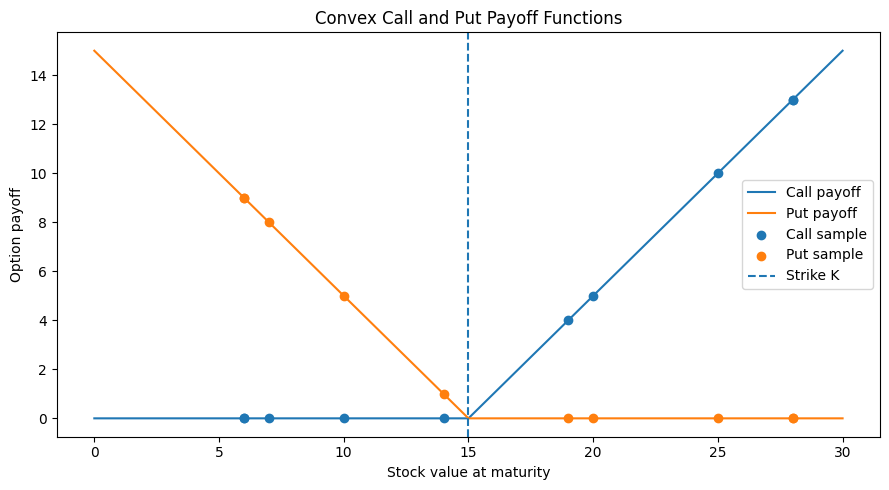

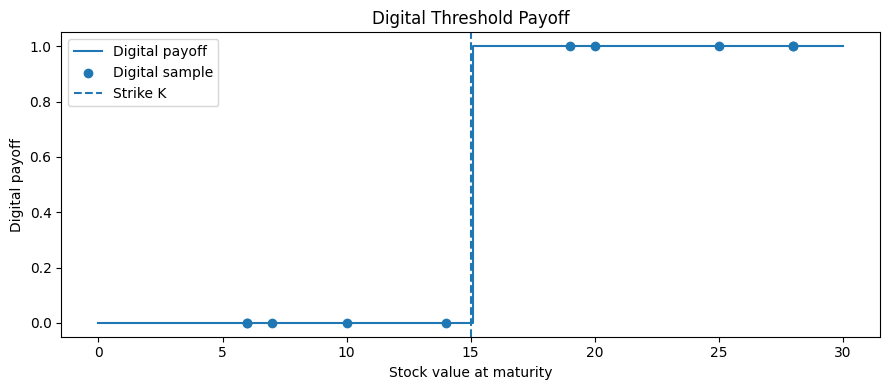

Call midpoint convexity test: True
Put midpoint convexity test: True
Digital midpoint convexity test: False

Digital test payoffs at S = 15, 16, 17:
[0. 1. 1.]


In [10]:
# Sort the random scenarios while preserving payoff alignment.
order = np.argsort(random_S1, kind="stable")

sorted_S1 = random_S1[order]
sorted_call = random_call[order]
sorted_put = random_put[order]
sorted_digital = random_digital[order]

sorted_payoff_table = pd.DataFrame(
    {
        "Stock value": sorted_S1,
        "Call payoff": sorted_call,
        "Put payoff": sorted_put,
        "Digital payoff": sorted_digital,
    }
)

print("Sorted realized payoff scenarios:")
display(sorted_payoff_table)


# Evaluate the exact payoff rules on a dense stock-value grid.
stock_grid = np.linspace(0.0, 30.0, 301)

grid_call, grid_put, grid_digital = option_payoffs(stock_grid, K)


# Plot the convex call and put payoff functions.
plt.figure(figsize=(9, 5))

plt.plot(stock_grid, grid_call, label="Call payoff")
plt.plot(stock_grid, grid_put, label="Put payoff")

plt.scatter(
    sorted_S1,
    sorted_call,
    label="Call sample",
)

plt.scatter(
    sorted_S1,
    sorted_put,
    label="Put sample",
)

plt.axvline(K, linestyle="--", label="Strike K")

plt.xlabel("Stock value at maturity")
plt.ylabel("Option payoff")
plt.title("Convex Call and Put Payoff Functions")
plt.legend()

plt.tight_layout()
plt.show()


# Plot the digital payoff separately because its payoff scale is different.
plt.figure(figsize=(9, 4))

plt.step(
    stock_grid,
    grid_digital,
    where="post",
    label="Digital payoff",
)

plt.scatter(
    sorted_S1,
    sorted_digital,
    label="Digital sample",
)

plt.axvline(K, linestyle="--", label="Strike K")

plt.xlabel("Stock value at maturity")
plt.ylabel("Digital payoff")
plt.title("Digital Threshold Payoff")
plt.legend()

plt.tight_layout()
plt.show()


# Midpoint convexity checks for the call and put.
test_points = np.array([10.0, 15.0, 20.0])
test_call, test_put, _ = option_payoffs(test_points, K)

call_midpoint_test = (
    test_call[1]
    <= 0.5 * test_call[0] + 0.5 * test_call[2]
)

put_midpoint_test = (
    test_put[1]
    <= 0.5 * test_put[0] + 0.5 * test_put[2]
)


# A midpoint counterexample for digital convexity.
digital_points = np.array([15.0, 16.0, 17.0])
_, _, digital_test_values = option_payoffs(digital_points, K)

digital_convexity_test = (
    digital_test_values[1]
    <= 0.5 * digital_test_values[0]
    + 0.5 * digital_test_values[2]
)

print("Call midpoint convexity test:", call_midpoint_test)
print("Put midpoint convexity test:", put_midpoint_test)
print("Digital midpoint convexity test:", digital_convexity_test)

print()
print("Digital test payoffs at S = 15, 16, 17:")
print(digital_test_values)

### Interpretation of Payoff Geometry and Convexity

The sorted scenarios and payoff plots make the geometry of the three contracts
visible across a wider range of stock values.

The numerical midpoint checks return

$$
\text{Call: True},
$$

$$
\text{Put: True},
$$

and

$$
\text{Digital: False}.
$$

These computational results are consistent with the mathematical analysis
above.

However, the roles of the mathematics and the numerical tests should be
distinguished carefully.

For the call and put, convexity follows from the structure of the payoff
functions themselves.

The numerical midpoint tests provide a concrete verification at selected
points.

For the digital payoff, the failed midpoint inequality provides a direct
counterexample, which is enough to establish that the function is not globally
convex.

---

#### 1. Sorted Payoff Scenarios

The random stock values are sorted as

$$
6,\;6,\;7,\;10,\;14,\;19,\;20,\;25,\;28,\;28.
$$

The corresponding payoff vectors are rearranged using the same sorting indices.

This is essential because each option payoff must remain attached to the stock
value that generated it.

The sorting operation changes only the presentation order.

It does not recalculate or alter the contract payoffs.

Thus, the ordered observations allow the payoff shape to be examined without
destroying the underlying stock-payoff relationship.

---

#### 2. Call Geometry

The call payoff is

$$
C(S)
=
\max(S-K,0).
$$

With

$$
K=15,
$$

the payoff is

$$
C(S)
=
\begin{cases}
0, & S\leq15,\\
S-15, & S>15.
\end{cases}
$$

Below the strike, the payoff is flat and has slope

$$
0.
$$

Above the strike, the payoff rises one-for-one with the stock and has slope

$$
1.
$$

Therefore, the slope changes from

$$
0
\longrightarrow
1.
$$

Because the slope increases rather than decreases, the call payoff is convex:

$$
\boxed{
C(S)=\max(S-K,0)
\text{ is convex in }S.
}
$$

The plot shows this structure clearly: a flat zero-payoff region is followed
by an upward-sloping linear region beginning at the strike.

---

#### 3. Put Geometry

The put payoff is

$$
P(S)
=
\max(K-S,0).
$$

With

$$
K=15,
$$

the payoff is

$$
P(S)
=
\begin{cases}
15-S, & S<15,\\
0, & S\geq15.
\end{cases}
$$

Below the strike, its slope is

$$
-1.
$$

Above the strike, its slope is

$$
0.
$$

Therefore, the slope changes from

$$
-1
\longrightarrow
0.
$$

Again, the slope increases rather than decreases.

Hence,

$$
\boxed{
P(S)=\max(K-S,0)
\text{ is convex in }S.
}
$$

The graph displays a downward-sloping linear payoff below the strike that
flattens at zero once the stock reaches the strike.

---

#### 4. Midpoint Illustration for the Call

The numerical call test uses the stock values

$$
10,\;15,\;20.
$$

Because

$$
15
=
\frac12(10)+\frac12(20),
$$

convexity requires

$$
C(15)
\leq
\frac12C(10)+\frac12C(20).
$$

The relevant payoffs are

$$
C(10)=0,
$$

$$
C(15)=0,
$$

and

$$
C(20)=5.
$$

Therefore,

$$
0
\leq
\frac12(0)+\frac12(5)
=
2.5.
$$

The inequality is satisfied, so Python returns

`True`.

This calculation illustrates the convexity property at these particular
points.

The general convexity conclusion comes from the payoff function's
nondecreasing slope.

---

#### 5. Midpoint Illustration for the Put

Using the same stock values,

$$
10,\;15,\;20,
$$

the put payoffs are

$$
P(10)=5,
$$

$$
P(15)=0,
$$

and

$$
P(20)=0.
$$

The midpoint inequality requires

$$
P(15)
\leq
\frac12P(10)+\frac12P(20).
$$

Therefore,

$$
0
\leq
\frac12(5)+\frac12(0)
=
2.5.
$$

Again, the inequality holds, so Python returns

`True`.

This numerical result is consistent with the analytical conclusion that the
put payoff is convex.

---

#### 6. Digital Threshold Geometry

The digital payoff used in this notebook is

$$
D(S)
=
\begin{cases}
0, & S\leq15,\\
1, & S>15.
\end{cases}
$$

Unlike the call and put, the digital does not have a continuous kink joining
two linear regions.

Instead, it has a discrete jump at the strike threshold.

Below and at the strike,

$$
D(S)=0.
$$

Immediately above the strike,

$$
D(S)=1.
$$

Once the threshold has been crossed, further increases in the stock value do
not increase the payoff.

This produces the step structure visible in the digital-payoff plot.

---

#### 7. Counterexample to Digital Convexity

The numerical test uses

$$
x=15,
\qquad
y=17,
$$

with midpoint

$$
\frac{x+y}{2}=16.
$$

The digital payoffs are

$$
D(15)=0,
$$

$$
D(16)=1,
$$

and

$$
D(17)=1.
$$

If the digital payoff were convex, it would have to satisfy

$$
D(16)
\leq
\frac12D(15)+\frac12D(17).
$$

Substituting the values gives

$$
1
\leq
\frac12(0)+\frac12(1).
$$

Therefore,

$$
1\leq0.5,
$$

which is false.

Hence,

$$
\boxed{
D(S)
\text{ is not globally convex.}
}
$$

Python reproduces this result by returning

`False`

for the digital midpoint convexity test.

Unlike the call and put, a single valid counterexample is enough to disprove
global convexity.

---

#### 8. Why the Dense Grid Is Used

The random sample contains only ten stock values.

Connecting those ten sample points alone could give a misleading impression of
the actual payoff functions, particularly near the strike.

The plotted curves therefore use a dense grid of stock values,

$$
0\leq S\leq30,
$$

and evaluate the exact payoff rules on that grid.

The random observations are then shown as markers on top of those contract
payoff functions.

This distinction is important:

$$
\boxed{
\text{sample points}
\neq
\text{definition of the payoff function}.
}
$$

The sample illustrates selected realized scenarios.

The dense curves represent numerical evaluations of the actual contractual
payoff rules.

---

#### 9. What “More Convex” Means in This Experiment

The capstone asks for a comparison of which option is more convex in realized
payoffs.

The analysis shows first that the contracts do not all belong to the same
convexity class:

$$
\boxed{
\text{Call: convex}
}
$$

$$
\boxed{
\text{Put: convex}
}
$$

$$
\boxed{
\text{Digital: not globally convex}.
}
$$

The call and put are both piecewise-linear convex functions.

In this simple formulation, neither should be described as universally
“more convex” than the other merely from the plotted payoff magnitudes.

Their convexity appears in opposite regions of the underlying stock space:

- the call has its kink at the strike and gains positive slope above it;
- the put has its kink at the strike and loses negative slope as it reaches
  zero.

The digital is qualitatively different because its threshold jump violates
global convexity.

Thus the most defensible conclusion from this experiment is not a numerical
ranking of the three contracts by convexity.

Rather,

$$
\boxed{
\text{the call and put are convex payoff functions, while the digital
threshold payoff is not globally convex.}
}
$$

---

#### 10. Financial Interpretation of Convexity

Convexity means that the option payoff reacts asymmetrically to movements in
the underlying stock.

For a call, downside movements below the strike cannot reduce the payoff below
zero, while sufficiently large upside movements continue to increase the
payoff.

For a put, sufficiently high stock values cannot reduce the payoff below zero,
while larger downward movements below the strike increase the payoff.

This asymmetric shape is a fundamental property of vanilla option payoffs.

The digital contract represents a different exposure: it is primarily
sensitive to whether a threshold is crossed rather than to the magnitude of
the movement once the condition is satisfied.

---

#### 11. Central Result of the Experiment

The fixed-seed experiment demonstrates that the same collection of underlying
stock scenarios can be transformed into fundamentally different payoff
geometries.

The analysis can be summarized as

$$
\boxed{
S
\longrightarrow
\begin{cases}
\max(S-K,0), & \text{call},\\
\max(K-S,0), & \text{put},\\
\mathbf{1}_{\{S>K\}}, & \text{digital}.
\end{cases}
}
$$

The resulting payoff structures differ not merely in numerical magnitude, but
in their mathematical geometry.

The call and put exhibit convexity.

The digital exhibits threshold behavior.

This completes the random-payoff and convexity component of the Chapter 1
capstone.

## Part 10 — Financial Conclusions

This capstone examined how three option contracts transform the same underlying
stock uncertainty into different state-dependent maturity payoffs.

The analysis began with the two-state stock payoff vector

$$
S_1=(20,5)
$$

and strike

$$
K=15.
$$

Using the common state ordering

$$
(\text{Up},\text{Down}),
$$

the three contracts produced

$$
C_1=(5,0)
$$

for the European call,

$$
P_1=(0,10)
$$

for the European put, and

$$
D_1=(1,0)
$$

for the one-unit digital call.

The notebook then extended these definitions to a reproducible set of generated
stock scenarios in order to study their payoff geometry.

---

### 1. One Underlying Uncertainty, Different Contracts

The same future stock value can generate very different cash flows depending on
the contract attached to it.

The three payoff rules are

$$
\boxed{
C(S)=\max(S-K,0)
}
$$

for the call,

$$
\boxed{
P(S)=\max(K-S,0)
}
$$

for the put, and

$$
\boxed{
D(S)=
\mathbf{1}_{\{S>K\}}
}
$$

for the digital convention used in this notebook.

Thus, the option contract does not create new stock states.

Instead, it maps an existing stock outcome into a contract-specific payoff:

$$
\boxed{
S
\longrightarrow
\text{contingent claim payoff}.
}
$$

This is the central financial idea behind the payoff explorer.

---

### 2. Call and Put Encode Opposite Directional Exposures

The call benefits from sufficiently high stock values.

For

$$
S>K,
$$

its payoff increases according to

$$
C(S)=S-K.
$$

For

$$
S\leq K,
$$

its payoff is floored at zero.

The put behaves in the opposite direction.

For

$$
S<K,
$$

its payoff increases as the stock falls:

$$
P(S)=K-S.
$$

For

$$
S\geq K,
$$

its payoff is zero.

Therefore,

$$
\boxed{
\text{call: exposure to sufficiently high }S
}
$$

while

$$
\boxed{
\text{put: exposure to sufficiently low }S.
}
$$

Both contracts have nonnegative maturity payoffs because exercise is optional.

---

### 3. The Digital Encodes a Threshold Event

The digital contract has a different economic structure.

Under the convention used here,

$$
D(S)=1
$$

when

$$
S>K,
$$

and

$$
D(S)=0
$$

otherwise.

Its payoff therefore depends on whether a threshold is crossed, not on the
magnitude by which the threshold is exceeded.

For example,

$$
S=19
$$

and

$$
S=28
$$

produce different call payoffs,

$$
4
\qquad\text{and}\qquad
13,
$$

but both produce the same digital payoff,

$$
1.
$$

Thus,

$$
\boxed{
\text{call payoff measures magnitude beyond the strike,}
}
$$

whereas

$$
\boxed{
\text{digital payoff records whether the threshold event occurs.}
}
$$

---

### 4. Probability Converts Payoff Vectors Into Distributions

Once probabilities are introduced, a contingent claim is no longer described
only by the set of possible payoffs.

It also has a probability distribution over those payoffs.

Using the explicit assumption

$$
P=(0.5,0.5),
$$

the expected payoff of a claim $X$ is

$$
E_P[X]=P^\top X,
$$

while its payoff standard deviation is

$$
\sigma_X
=
\sqrt{
E_P[(X-E_P[X])^2]
}.
$$

For the original two-state example, the results were

| Claim | Expected payoff | Standard deviation |
|---|---:|---:|
| Call | $2.5$ | $2.5$ |
| Put | $5.0$ | $5.0$ |
| Digital | $0.5$ | $0.5$ |

These quantities summarize the payoff distribution under the assumed
probabilities.

They do not introduce additional future states.

---

### 5. Expected Payoff and Price Are Different Objects

A central distinction in the notebook is

$$
\boxed{
E_P[X]
\neq
X_0
}
$$

in general.

Expected payoff is a statistical quantity calculated from future payoffs and a
probability distribution.

A time-$0$ price is a financial valuation quantity.

Nothing in the Chapter 1 payoff experiment establishes that the physical
expected payoff of a claim must equal its current price.

Pricing requires additional market structure that is developed later in the
financial-theory sequence.

Likewise,

$$
\boxed{
\text{payoff}
\neq
\text{profit}.
}
$$

Profit would also require accounting for the amount paid or received for the
contract.

---

### 6. Standard Deviation Must Be Interpreted With Scale

The raw payoff standard deviations were

$$
2.5,\qquad5,\qquad0.5
$$

for the call, put, and digital respectively.

The put therefore has the greatest absolute payoff dispersion in this specific
numerical experiment.

However, the contracts have different payoff scales.

The digital is deliberately defined to pay only one unit, while the call and
put can generate larger cash flows.

Therefore, raw standard deviation alone does not justify a universal ranking of
the contracts by economic risk.

The defensible conclusion is narrower:

$$
\boxed{
\text{standard deviation measures payoff dispersion under the chosen
probabilities and contract scaling.}
}
$$

---

### 7. Convexity Is a Property of the Payoff Function

The random scenarios help visualize the option payoffs, but convexity is a
mathematical property of the underlying functions.

For the call,

$$
C(S)=\max(S-K,0),
$$

the slope changes from

$$
0
\longrightarrow
1.
$$

For the put,

$$
P(S)=\max(K-S,0),
$$

the slope changes from

$$
-1
\longrightarrow
0.
$$

Both slopes are nondecreasing, so

$$
\boxed{
\text{the call and put payoff functions are convex.}
}
$$

The digital payoff instead has a discontinuous threshold jump.

A direct midpoint counterexample shows that

$$
\boxed{
\text{the digital payoff used here is not globally convex.}
}
$$

Thus the contracts differ not only in payoff magnitude, but also in payoff
geometry.

---

### 8. Randomness Entered the Scenarios, Not the Contract Rules

The fixed-seed experiment generated

$$
6,19,28,14,10,7,28,20,6,25.
$$

These stock values were generated pseudo-randomly.

Once a stock value and strike are specified, however, the corresponding option
payoffs are determined completely by the contract definitions.

Thus the experiment separates

$$
\boxed{
\text{random scenario generation}
}
$$

from

$$
\boxed{
\text{deterministic payoff transformation}.
}
$$

The fixed seed

$$
42
$$

ensures that the scenario experiment is reproducible.

---

### 9. Python as a Representation of the Mathematics

The notebook does not use Python as a substitute for the financial reasoning.

Instead, each computational operation represents a previously defined
mathematical object.

Examples include

`np.maximum(stock_payoffs - strike, 0.0)`

for

$$
\max(S-K,0),
$$

`np.dot(probabilities, payoff)`

for

$$
E_P[X],
$$

and

`np.sqrt(variance)`

for

$$
\sigma_X.
$$

The reusable function

`option_payoffs(...)`

encodes the contract definitions once and applies them consistently to new
underlying scenarios.

The helper function

`payoff_moments(...)`

does the same for expectation, variance, and standard deviation.

This creates the modeling chain

$$
\boxed{
\text{financial definition}
\rightarrow
\text{mathematical representation}
\rightarrow
\text{Python implementation}
\rightarrow
\text{numerical verification}.
}
$$

---

### 10. Main Takeaway

The central lesson of the capstone is that an option is a state-contingent
transformation of an underlying financial outcome.

Starting from a stock value $S$, the contract determines a payoff according to
a specified mathematical rule.

For the contracts studied here,

$$
\boxed{
S
\longrightarrow
\begin{cases}
\max(S-K,0), & \text{call},\\
\max(K-S,0), & \text{put},\\
\mathbf{1}_{\{S>K\}}, & \text{digital}.
\end{cases}
}
$$

Probability can then be introduced to summarize the resulting payoff
distribution through quantities such as expected payoff and standard
deviation.

The resulting framework connects

$$
\boxed{
\text{states}
\rightarrow
\text{payoffs}
\rightarrow
\text{probabilities}
\rightarrow
\text{moments}
\rightarrow
\text{payoff geometry}.
}
$$

This provides the foundation for later questions in financial theory, where
contingent claims are not only described by their future payoffs but are also
hedged and priced using traded financial assets.

---

### Scope of the Analysis

This notebook is a discrete numerical payoff experiment.

It does not model

- observed historical stock-price dynamics;
- a calibrated probability distribution;
- option premiums;
- transaction costs;
- dynamic hedging;
- or arbitrage-free option pricing.

Those omissions are intentional.

The purpose of the Chapter 1 capstone is to establish a precise understanding
of state-dependent payoffs, probability-weighted payoff summaries, reusable
Python representations, reproducibility, and payoff geometry before more
advanced pricing and hedging models are introduced.

## Part 11 — Reproducibility and Validation Checks

Before treating the notebook as a finished portfolio artifact, I perform a set
of internal validation checks.

The purpose is to confirm that the notebook's main results are mutually
consistent and can be reproduced from the definitions established earlier.

The checks verify that:

- the original two-state payoff vectors match the hand-derived call, put, and
  digital payoffs;
- the reusable payoff function reproduces those same results;
- the probability vector is valid;
- the computed payoff moments match the analytical calculations;
- the random experiment is reproducible under the fixed seed;
- the generated stock values stay inside the intended range;
- sorting preserves the scenario values while ordering them correctly;
- the dense-grid payoff calculations obey the same contract definitions;
- the selected call and put midpoint tests satisfy the convexity inequality;
- the digital midpoint example violates the convexity inequality as intended.

A successful fresh-runtime execution of all cells will provide an additional
reproducibility check by confirming that the notebook does not depend on hidden
variables or an accidental execution order.

In [11]:
expected_call = np.array([5.0, 0.0])
expected_put = np.array([0.0, 10.0])
expected_digital = np.array([1.0, 0.0])

expected_statistics = {
    "Call": {
        "Expected Payoff": 2.5,
        "Variance": 6.25,
        "Standard Deviation": 2.5,
    },
    "Put": {
        "Expected Payoff": 5.0,
        "Variance": 25.0,
        "Standard Deviation": 5.0,
    },
    "Digital": {
        "Expected Payoff": 0.5,
        "Variance": 0.25,
        "Standard Deviation": 0.5,
    },
}

checks = {
    "Stock payoff vector has two states":
        S1.shape == (2,),

    "State labels match stock payoff length":
        len(states) == len(S1),

    "Call payoff matches hand derivation":
        np.allclose(call_payoff, expected_call),

    "Put payoff matches hand derivation":
        np.allclose(put_payoff, expected_put),

    "Digital payoff matches hand derivation":
        np.allclose(digital_payoff, expected_digital),

    "Reusable function reproduces call payoff":
        np.allclose(call_from_function, expected_call),

    "Reusable function reproduces put payoff":
        np.allclose(put_from_function, expected_put),

    "Reusable function reproduces digital payoff":
        np.allclose(digital_from_function, expected_digital),

    "State probabilities sum to one":
        np.isclose(P.sum(), 1.0),

    "State probabilities are nonnegative":
        np.all(P >= 0.0),

    "Call expected payoff matches derivation":
        np.isclose(
            statistics_table.loc["Call", "Expected Payoff"],
            expected_statistics["Call"]["Expected Payoff"],
        ),

    "Call variance matches derivation":
        np.isclose(
            statistics_table.loc["Call", "Variance"],
            expected_statistics["Call"]["Variance"],
        ),

    "Call standard deviation matches derivation":
        np.isclose(
            statistics_table.loc["Call", "Standard Deviation"],
            expected_statistics["Call"]["Standard Deviation"],
        ),

    "Put expected payoff matches derivation":
        np.isclose(
            statistics_table.loc["Put", "Expected Payoff"],
            expected_statistics["Put"]["Expected Payoff"],
        ),

    "Put variance matches derivation":
        np.isclose(
            statistics_table.loc["Put", "Variance"],
            expected_statistics["Put"]["Variance"],
        ),

    "Put standard deviation matches derivation":
        np.isclose(
            statistics_table.loc["Put", "Standard Deviation"],
            expected_statistics["Put"]["Standard Deviation"],
        ),

    "Digital expected payoff matches derivation":
        np.isclose(
            statistics_table.loc["Digital", "Expected Payoff"],
            expected_statistics["Digital"]["Expected Payoff"],
        ),

    "Digital variance matches derivation":
        np.isclose(
            statistics_table.loc["Digital", "Variance"],
            expected_statistics["Digital"]["Variance"],
        ),

    "Digital standard deviation matches derivation":
        np.isclose(
            statistics_table.loc["Digital", "Standard Deviation"],
            expected_statistics["Digital"]["Standard Deviation"],
        ),

    "Fixed-seed experiment is reproducible":
        reproducible,

    "Random experiment contains ten scenarios":
        len(random_S1) == 10,

    "Random stock values remain in the intended range":
        np.all((random_S1 >= 0) & (random_S1 <= 30)),

    "Sorted scenarios equal NumPy sorted scenarios":
        np.array_equal(sorted_S1, np.sort(random_S1)),

    "Dense-grid call obeys call definition":
        np.allclose(
            grid_call,
            np.maximum(stock_grid - K, 0.0),
        ),

    "Dense-grid put obeys put definition":
        np.allclose(
            grid_put,
            np.maximum(K - stock_grid, 0.0),
        ),

    "Dense-grid digital obeys digital definition":
        np.allclose(
            grid_digital,
            (stock_grid > K).astype(float),
        ),

    "Call midpoint convexity illustration passes":
        bool(call_midpoint_test),

    "Put midpoint convexity illustration passes":
        bool(put_midpoint_test),

    "Digital convexity counterexample fails as intended":
        not bool(digital_convexity_test),
}

for description, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} — {description}")

assert all(checks.values())

print()
print("All Chapter 1 capstone validation checks passed.")

PASS — Stock payoff vector has two states
PASS — State labels match stock payoff length
PASS — Call payoff matches hand derivation
PASS — Put payoff matches hand derivation
PASS — Digital payoff matches hand derivation
PASS — Reusable function reproduces call payoff
PASS — Reusable function reproduces put payoff
PASS — Reusable function reproduces digital payoff
PASS — State probabilities sum to one
PASS — State probabilities are nonnegative
PASS — Call expected payoff matches derivation
PASS — Call variance matches derivation
PASS — Call standard deviation matches derivation
PASS — Put expected payoff matches derivation
PASS — Put variance matches derivation
PASS — Put standard deviation matches derivation
PASS — Digital expected payoff matches derivation
PASS — Digital variance matches derivation
PASS — Digital standard deviation matches derivation
PASS — Fixed-seed experiment is reproducible
PASS — Random experiment contains ten scenarios
PASS — Random stock values remain in the int